<a href="https://colab.research.google.com/github/Jaanhavi28/DSC212Assignment/blob/main/DSC212_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Number of nodes: 34
Number of edges: 78


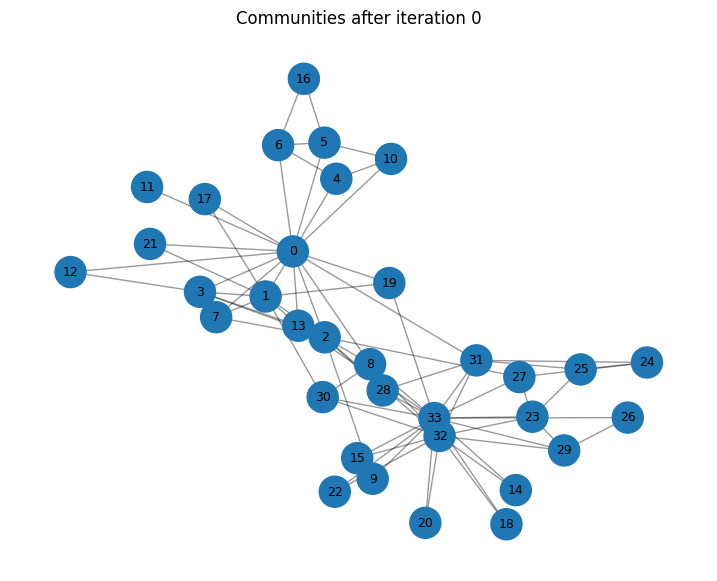


Largest eigenvalue: 17.107386763280683
Modularity gain: 1.1983892176199866
Iteration: 1
Community 1: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Community 2: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


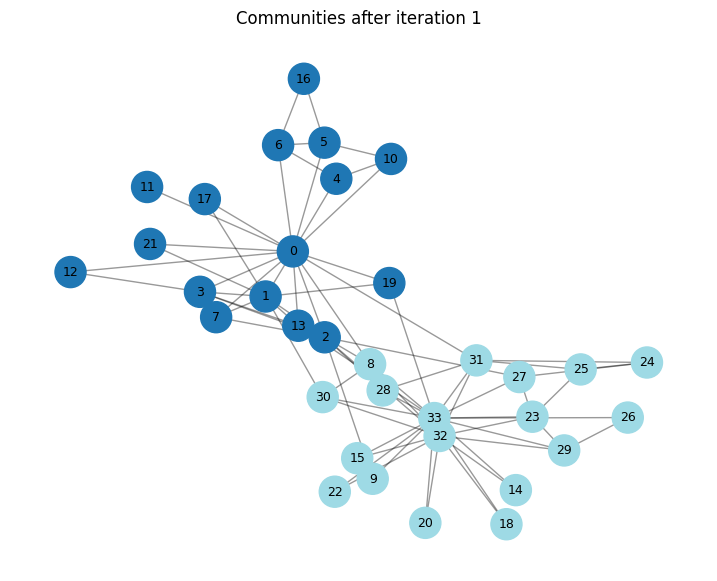


Largest eigenvalue: 15.42726910447759
Unable to create two nonempty communities.

Largest eigenvalue: 15.679107949724372
Unable to create two nonempty communities.

Final communities:
Community 1 : [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Community 2 : [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


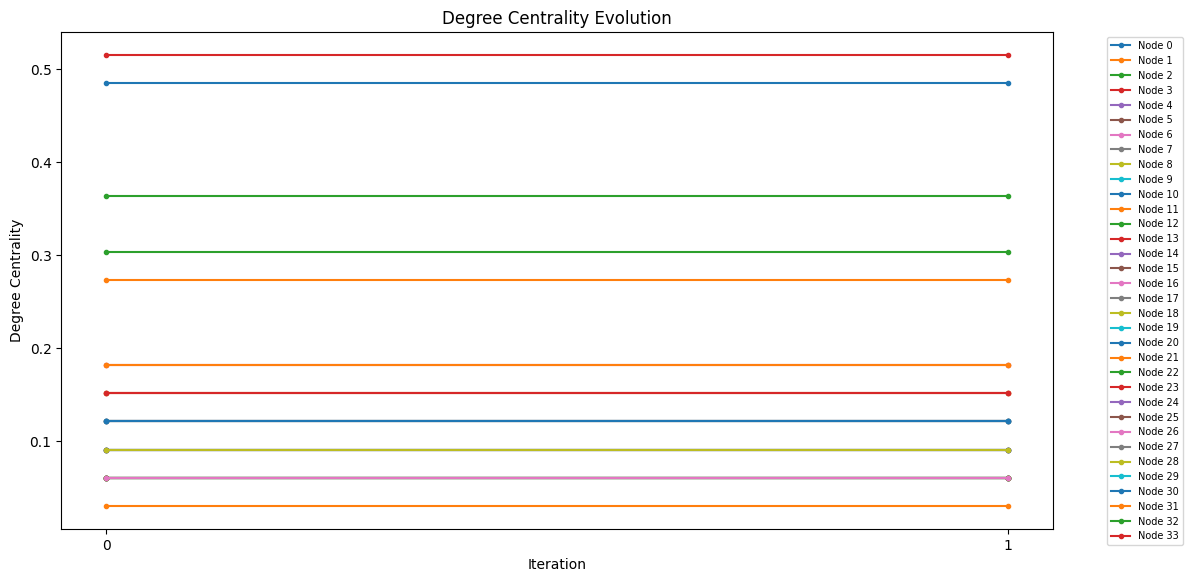

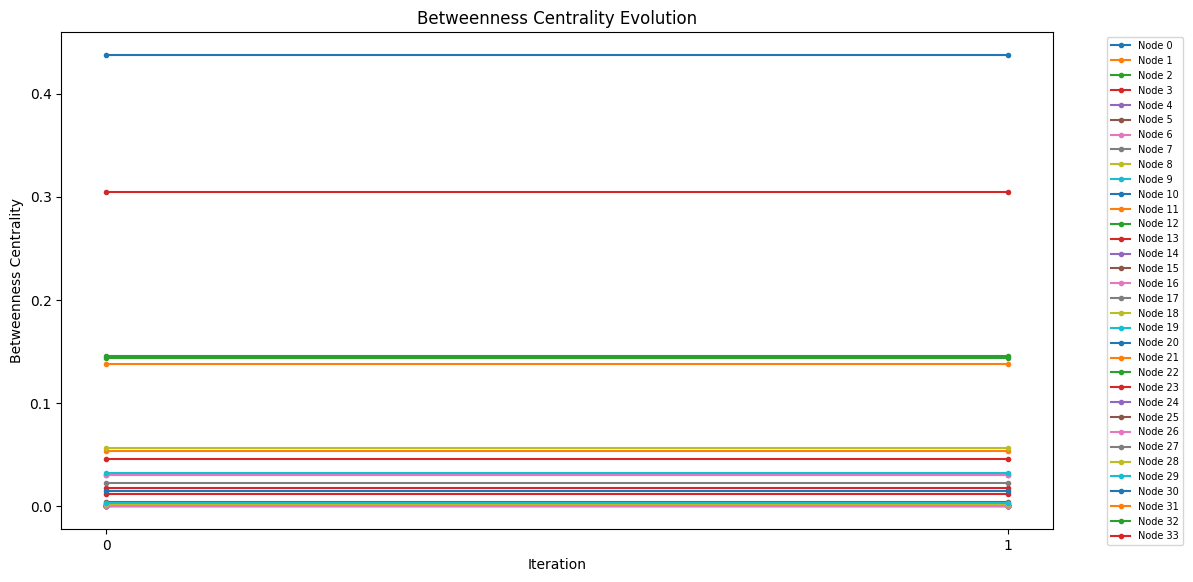

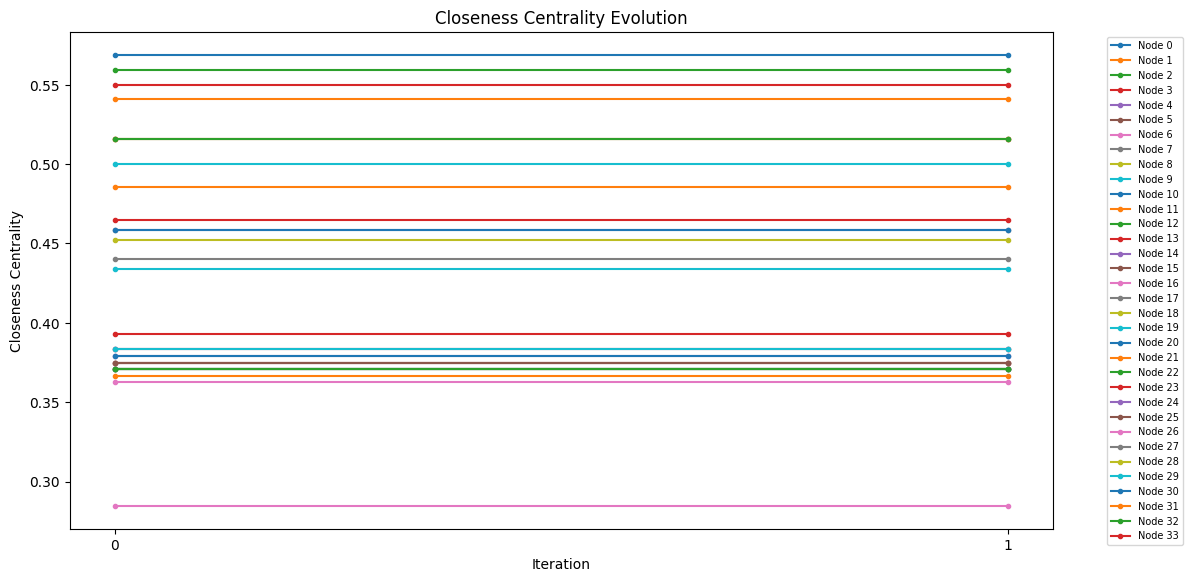

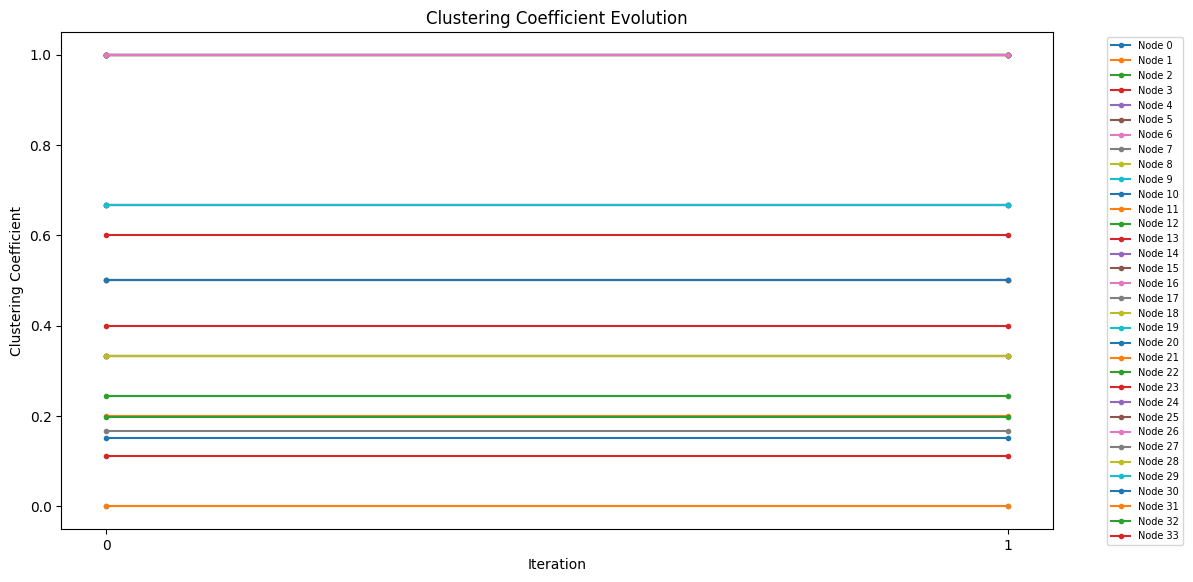

In [ ]:

import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Create the Karate Club graph
G = nx.karate_club_graph()
n = G.number_of_nodes()
m = G.number_of_edges()
print("Number of nodes:", n)
print("Number of edges:", m)

# Step 2: Calculate the modularity matrix
# B = A - (k k^T)/(2m)
A = nx.to_numpy_array(G)
degrees = np.array([G.degree(i) for i in G.nodes()])
B = A - np.outer(degrees, degrees) / (2 * m)

# Step 3: Calculate node metrics
def calculate_metrics(G):
  degree = nx.degree_centrality(G)
  betweenness = nx.betweenness_centrality(G)
  closeness = nx.closeness_centrality(G)
  clustering = nx.clustering(G)
  return {
        "Degree Centrality": degree,
        "Betweenness Centrality": betweenness,
        "Closeness Centrality": closeness,
        "Clustering Coefficient": clustering
    }

# Step 4: Visualize the communities
# Calculate the layout only once.
# This keeps node positions fixed in every iteration.
pos = nx.spring_layout(G, seed=42)
def draw_communities(G, communities, iteration):
    plt.figure(figsize=(9, 7))
    colors = plt.cm.tab20(
        np.linspace(0, 1, max(len(communities), 1))
    )
    node_colors = {}
    for i, community in enumerate(communities):
        for node in community:
            node_colors[node] = colors[i]
    nx.draw_networkx_edges(
        G, pos,
        alpha=0.4
    )
    nx.draw_networkx_nodes(
        G, pos,
        node_color=[node_colors[node] for node in G.nodes()],
        node_size=500
    )
    nx.draw_networkx_labels(
        G, pos,
        font_size=9
    )
    plt.title("Communities after iteration " + str(iteration))
    plt.axis("off")
    plt.show()

# Step 5: Recursive spectral partitioning
def recursive_partition(G, B):
    # Initially, the entire graph is one community.
    communities = [list(G.nodes())]
    # Communities that still need to be examined.
    pending = [list(G.nodes())]
    iteration = 0
    # Store metric values after every split.
    metric_history = []
    # Initial visualization and metrics.
    metric_history.append(calculate_metrics(G))
    draw_communities(G, communities, iteration)
    while pending:
        current = pending.pop(0)
        # Get the indices of the nodes in this community.
        indices = current
        # Restrict the original modularity matrix to the current community.
        B_sub = B[np.ix_(indices, indices)]
        # Calculate eigenvalues and eigenvectors.
        eigenvalues, eigenvectors = np.linalg.eigh(B_sub)
        # Find the largest eigenvalue.
        largest_index = np.argmax(eigenvalues)
        largest_eigenvalue = eigenvalues[largest_index]
        leading_eigenvector = eigenvectors[:, largest_index]
        print("\nLargest eigenvalue:", largest_eigenvalue)
        # Stop if the largest eigenvalue is nonpositive.
        if largest_eigenvalue <= 1e-10:
            print("No further improvement possible.")
            continue
        # Divide nodes according to the signs of the leading eigenvector.
        community1 = []
        community2 = []
        for i, node in enumerate(current):
            if leading_eigenvector[i] >= 0:
                community1.append(node)
            else:
                community2.append(node)
        # Avoid an empty community.
        if len(community1) == 0 or len(community2) == 0:
            print("Unable to create two nonempty communities.")
            continue
        # Calculate the actual modularity gain from this discrete split.
        s = np.where(leading_eigenvector >= 0, 1, -1)
        gain = (s @ B_sub @ s) / (4 * m)
        print("Modularity gain:", gain)
        # Accept only a split that improves modularity.
        if gain <= 1e-10:
            print("The rounded split does not improve modularity.")
            continue
        # Replace the old community with two new ones.
        communities.remove(current)
        communities.append(community1)
        communities.append(community2)
        iteration += 1
        print("Iteration:", iteration)
        print("Community 1:", community1)
        print("Community 2:", community2)
        # Add the new communities to the pending list.
        pending.append(community1)
        pending.append(community2)
        # Visualize the graph after this split.
        draw_communities(G, communities, iteration)
        # Calculate metrics after every split.
        metric_history.append(calculate_metrics(G))
    return communities, metric_history

# Step 6: Run the algorithm
final_communities, metric_history = recursive_partition(G, B)
print("\nFinal communities:")
for i, community in enumerate(final_communities):
    print("Community", i + 1, ":", community)

# Step 7: Plot the evolution of node metrics
metric_names = [
    "Degree Centrality",
    "Betweenness Centrality",
    "Closeness Centrality",
    "Clustering Coefficient"
]
nodes = list(G.nodes())
iterations = range(len(metric_history))
for metric_name in metric_names:
    plt.figure(figsize=(12, 6))
    for node in nodes:
        values = [
            history[metric_name][node]
            for history in metric_history
        ]
        plt.plot(
            iterations,
            values,
            marker="o",
            markersize=3,
            label="Node " + str(node)
        )
    plt.title(metric_name + " Evolution")
    plt.xlabel("Iteration")
    plt.ylabel(metric_name)
    plt.xticks(list(iterations))
    plt.legend(
        bbox_to_anchor=(1.05, 1),
        loc="upper left",
        fontsize=7
    )
    plt.tight_layout()
    plt.show()